In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_abnormal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_normal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv


In [3]:
import os
print(os.listdir('/kaggle/input/heartbeat/'))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/heartbeat/'

In [4]:
import os
print(os.listdir('/kaggle/input/heartbeat/'))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/heartbeat/'

In [6]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_abnormal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_normal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

# بارگذاری دیتاست
df = pd.read_csv('/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv', header=None)
print("Shape:", df.shape)
print("Labels:", df.iloc[:, 187].value_counts())

Shape: (87554, 188)
Labels: 187
0.0    72471
4.0     6431
2.0     5788
1.0     2223
3.0      641
Name: count, dtype: int64


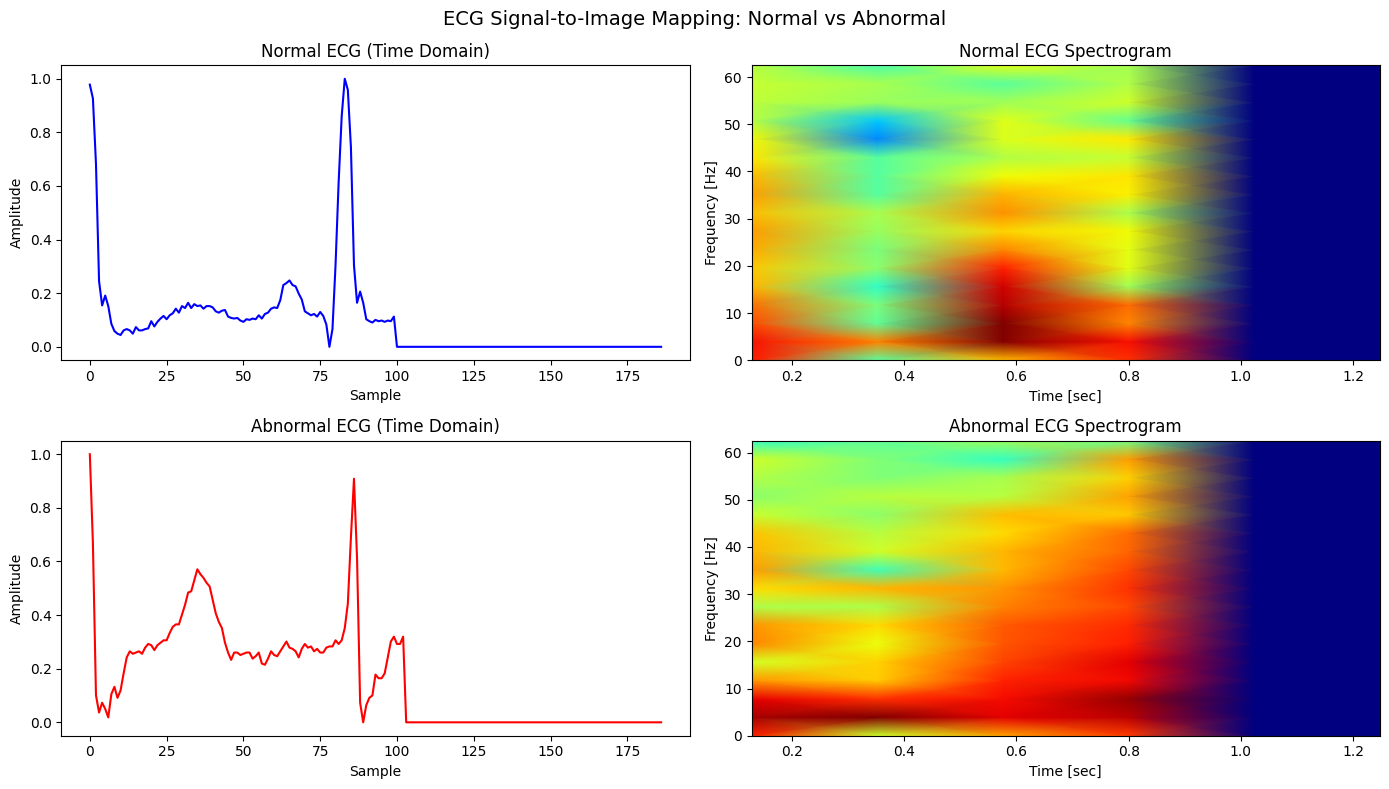

تصویر ذخیره شد!


In [8]:
# انتخاب نمونه‌ها و رسم مقایسه‌ای
ecg_data = df.iloc[:, :187].values
labels = df.iloc[:, 187].values

fs = 125  # فرکانس نمونه‌برداری دیتاست MIT-BIH

normal_ecg = ecg_data[labels == 0.0][0]
abnormal_ecg = ecg_data[labels == 1.0][0]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('ECG Signal-to-Image Mapping: Normal vs Abnormal', fontsize=14)

# سیگنال نرمال
axes[0,0].plot(normal_ecg, color='blue')
axes[0,0].set_title('Normal ECG (Time Domain)')
axes[0,0].set_xlabel('Sample')
axes[0,0].set_ylabel('Amplitude')

# Spectrogram نرمال
f, t, spec = signal.spectrogram(normal_ecg, fs, nperseg=32)
axes[0,1].pcolormesh(t, f, 10*np.log10(spec + 1e-10), cmap='jet', shading='gouraud')
axes[0,1].set_title('Normal ECG Spectrogram')
axes[0,1].set_ylabel('Frequency [Hz]')
axes[0,1].set_xlabel('Time [sec]')

# سیگنال بیمار
axes[1,0].plot(abnormal_ecg, color='red')
axes[1,0].set_title('Abnormal ECG (Time Domain)')
axes[1,0].set_xlabel('Sample')
axes[1,0].set_ylabel('Amplitude')

# Spectrogram بیمار
f, t, spec = signal.spectrogram(abnormal_ecg, fs, nperseg=32)
axes[1,1].pcolormesh(t, f, 10*np.log10(spec + 1e-10), cmap='jet', shading='gouraud')
axes[1,1].set_title('Abnormal ECG Spectrogram')
axes[1,1].set_ylabel('Frequency [Hz]')
axes[1,1].set_xlabel('Time [sec]')

plt.tight_layout()
plt.savefig('/kaggle/working/ecg_comparison.png', dpi=300)
plt.show()
print("تصویر ذخیره شد!")

2026-06-13 12:07:14.800612: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781352435.116971      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781352435.221799      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781352435.971890      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781352435.971939      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781352435.971943      58 computation_placer.cc:177] computation placer alr

Converting ECG to spectrograms...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-06-13 12:07:34.263048: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,657 (307.25 KB)

 Trainable params: 78,657 (307.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.6175 - loss: 0.6670 - val_accuracy: 0.0950 - val_loss: 0.9626
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6500 - loss: 0.6490 - val_accuracy: 0.1450 - val_loss: 0.8393
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6550 - loss: 0.6355 - val_accuracy: 0.1500 - val_loss: 0.9087
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6662 - loss: 0.6211 - val_accuracy: 0.2200 - val_loss: 0.8088
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6800 - loss: 0.6135 - val_accuracy: 0.1500 - val_loss: 1.1163
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7025 - loss: 0.5888 - val_accuracy: 0.3450 - val_loss: 0.7761
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7300 - loss: 0.5596 - val_accuracy: 0.5100 - val_loss: 0.7638
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7563 - loss: 0.5414 - val_accuracy: 0.4200 - v

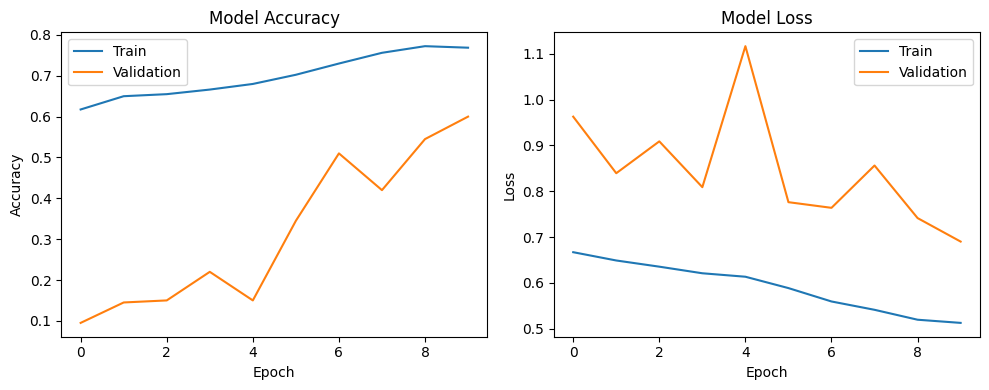

Done!


In [9]:
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from scipy import signal as scipy_signal

# ساخت تصاویر spectrogram از کل دیتاست (500 نمونه برای سرعت)
def ecg_to_spectrogram(ecg_beat, fs=125):
    _, _, spec = scipy_signal.spectrogram(ecg_beat, fs, nperseg=32)
    spec_db = 10 * np.log10(spec + 1e-10)
    # resize به 32x32
    from scipy.ndimage import zoom
    target = (32 / spec_db.shape[0], 32 / spec_db.shape[1])
    return zoom(spec_db, target)

# انتخاب 500 نمونه نرمال و 500 غیرنرمال
normal_samples = ecg_data[labels == 0.0][:500]
abnormal_samples = ecg_data[labels == 1.0][:500]

print("Converting ECG to spectrograms...")
X_normal = np.array([ecg_to_spectrogram(s) for s in normal_samples])
X_abnormal = np.array([ecg_to_spectrogram(s) for s in abnormal_samples])

X = np.concatenate([X_normal, X_abnormal])
y = np.array([0]*500 + [1]*500)

X = X[..., np.newaxis]  # اضافه کردن channel dimension
X = (X - X.min()) / (X.max() - X.min())  # normalize

# ساخت مدل CNN
model = keras.Sequential([
    layers.Conv2D(16, (3,3), activation='relu', input_shape=(32,32,1)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Train
history = model.fit(X, y, epochs=10, validation_split=0.2, batch_size=32)
print("Training complete!")

# رسم نتایج
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/cnn_results.png', dpi=300)
plt.show()
print("Done!")